# TP2 : un réseau pour classer les images CIFAR-10

Objectif : classer des photos en 10 classes (avion, chat, camion...) avec un réseau de neurones qui lit les pixels de l'image. Le chargement, l'entraînement et les graphiques sont fournis : vous écrivez les réseaux, vous les entraînez et vous choisissez le meilleur parmi trois architectures.

L'énoncé complet, avec les critères de réussite, est dans `enonce.md`.

**Corrigé.** *Les sorties enregistrées dans ce notebook viennent d'une exécution dans Google Colab sur GPU A100, avec la graine fixée. Sur un autre GPU ou sur CPU, certaines valeurs peuvent légèrement différer : PyTorch ne garantit pas des résultats identiques d'une plateforme à l'autre.*

## Installation

Cette cellule écrit `requirements-colab.txt` (les versions de la formation, alignées sur le runtime Colab), puis l'installe avec uv. Les paquets déjà présents à la bonne version ne sont pas réinstallés. Hors de Colab, elle n'installe rien : l'environnement uv du projet contient déjà ces versions.

In [ ]:
import importlib.util
from pathlib import Path

Path("requirements-colab.txt").write_text("""torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
scikit-learn==1.6.1
pandas==2.2.2; python_version < "3.13"
pandas==2.2.3; python_version >= "3.13"
pyarrow>=14
tensorboard==2.21.0
torchviz==0.0.3
onnx==1.23.0
onnxruntime==1.30.0
onnxscript==0.7.2
torchserve==0.12.0
torch-model-archiver==0.12.0
""")

if importlib.util.find_spec("google.colab") is not None:
    %pip install -q --progress-bar off uv
    !uv pip install --system -q -r requirements-colab.txt
else:
    print("Hors Colab : environnement uv du projet, rien à installer.")

## Préparation (fournie)

**Données** : CIFAR-10 (Krizhevsky, Nair et Hinton, 2009), fourni par torchvision : des photos couleur de 32 x 32 pixels, en 10 classes (avion, automobile, oiseau, chat, cerf, chien, grenouille, cheval, bateau, camion). Le site du jeu ne donne pas de licence ; il demande de citer le rapport *Learning Multiple Layers of Features from Tiny Images* (Krizhevsky, 2009). Tous les TP utilisent les mêmes images : 5000 d'entraînement et 1000 de validation, tirées de l'entraînement de CIFAR-10, et 1000 de test.

La fonction ci-dessous télécharge CIFAR-10 et range les images tirées dans des dossiers : `cifar10/<partie>/<classe>/`.

In [ ]:
def preparer_archive_cifar10(racine="data"):
    """Place les fichiers de CIFAR-10 dans racine/cifar-10-batches-py sans passer par le serveur d'origine, lent.

    Dans l'ordre : fichiers déjà décompressés ; archive déposée dans la session (cifar-10-python.tar.gz ou
    cifar-10-batches-py.tar.gz, dans le dossier du notebook ou dans racine) ; archive d'origine copiée sur le
    Google Drive de la formation. Si rien n'aboutit, torchvision télécharge ensuite depuis le serveur d'origine ;
    dans tous les cas, il vérifie l'intégrité des fichiers.
    """
    import tarfile
    import urllib.request
    from pathlib import Path

    if Path(racine, "cifar-10-batches-py").exists():
        return
    noms = ("cifar-10-python.tar.gz", "cifar-10-batches-py.tar.gz")
    deposees = [Path(dossier, nom) for dossier in (".", racine) for nom in noms if Path(dossier, nom).exists()]
    if deposees:
        archive = deposees[0]
        print(f"Archive trouvée : {archive}")
    else:
        archive = Path(racine, "cifar-10-python.tar.gz")
        archive.parent.mkdir(parents=True, exist_ok=True)
        url = ("https://drive.usercontent.google.com/download?id=1kyq-1VhOPNr2Bo0w5DiLYuNghOdOWl0a"
               "&export=download&confirm=t")
        print("Téléchargement de CIFAR-10 depuis le Google Drive de la formation (170 Mo)...")
        try:
            urllib.request.urlretrieve(url, archive)
        except OSError as erreur:
            print(f"Google Drive indisponible ({erreur}) : téléchargement depuis le serveur d'origine.")
            return
    try:
        with tarfile.open(archive) as contenu:
            contenu.extractall(racine, filter="data")
    except tarfile.TarError:
        print(f"{archive} n'est pas une archive valide : téléchargement depuis le serveur d'origine.")


def charger_cifar10(dossier="cifar10", n_train=5000, n_val=1000, n_test=1000, seed=0):
    """Images CIFAR-10 au format ImageFolder : dossier/<partie>/<classe>/<image>.png, classes en français.

    Tirages à graine fixe, les mêmes pour tous les TP : n_train et n_val images prises dans les 50 000 images
    d'entraînement de CIFAR-10, sans recouvrement, et n_test dans les 10 000 images de test. Une partie déjà
    présente n'est pas réécrite ; l'écriture passe par un dossier temporaire propre à chaque exécution, renommé à
    la fin : une écriture interrompue n'est jamais prise pour une partie complète, et deux notebooks lancés en même
    temps sur la même machine ne se gênent pas. Les fichiers de CIFAR-10 sont d'abord
    récupérés par preparer_archive_cifar10 (archive déposée dans la session, ou Google Drive de la formation).
    """
    import shutil
    import tempfile
    from pathlib import Path

    import torch
    from torchvision.datasets import CIFAR10

    noms = ["avion", "automobile", "oiseau", "chat", "cerf", "chien", "grenouille", "cheval", "bateau", "camion"]
    generateur = torch.Generator().manual_seed(seed)
    ordre = torch.randperm(50000, generator=generateur).tolist()
    parties = {"train": (True, ordre[:n_train]),
               "val": (True, ordre[n_train:n_train + n_val]),
               "test": (False, torch.randperm(10000, generator=generateur)[:n_test].tolist())}
    preparer_archive_cifar10()
    for partie, (entrainement, indices) in parties.items():
        if Path(dossier, partie).exists():
            continue
        source = CIFAR10("data", train=entrainement, download=True)
        Path(dossier).mkdir(parents=True, exist_ok=True)
        temporaire = Path(tempfile.mkdtemp(prefix=f"{partie}.tmp", dir=dossier))
        for numero, indice in enumerate(indices):
            image, label = source[indice]
            sortie = Path(temporaire, noms[label], f"{numero:05d}.png")
            sortie.parent.mkdir(parents=True, exist_ok=True)
            image.save(sortie)
        try:
            temporaire.rename(Path(dossier, partie))
        except OSError:
            # Un autre notebook a fini d'écrire cette partie pendant ce temps : on garde la sienne.
            if not Path(dossier, partie).exists():
                raise
            shutil.rmtree(temporaire)

In [3]:
charger_cifar10()

Téléchargement de CIFAR-10 depuis le Google Drive de la formation (170 Mo)...


## Étape 0 : découvrir les données (fournie)

Exécutez les cellules, puis répondez aux questions.

In [4]:
from pathlib import Path

for partie in ("train", "val", "test"):
    effectifs = {c.name: len(list(c.iterdir())) for c in sorted(Path(f"cifar10/{partie}").iterdir())}
    print(partie, sum(effectifs.values()), effectifs)

train 5000 {'automobile': 510, 'avion': 511, 'bateau': 500, 'camion': 520, 'cerf': 502, 'chat': 509, 'cheval': 470, 'chien': 472, 'grenouille': 500, 'oiseau': 506}
val 1000 {'automobile': 103, 'avion': 109, 'bateau': 102, 'camion': 84, 'cerf': 96, 'chat': 112, 'cheval': 95, 'chien': 111, 'grenouille': 99, 'oiseau': 89}
test 1000 {'automobile': 100, 'avion': 98, 'bateau': 109, 'camion': 90, 'cerf': 104, 'chat': 107, 'cheval': 100, 'chien': 97, 'grenouille': 104, 'oiseau': 91}


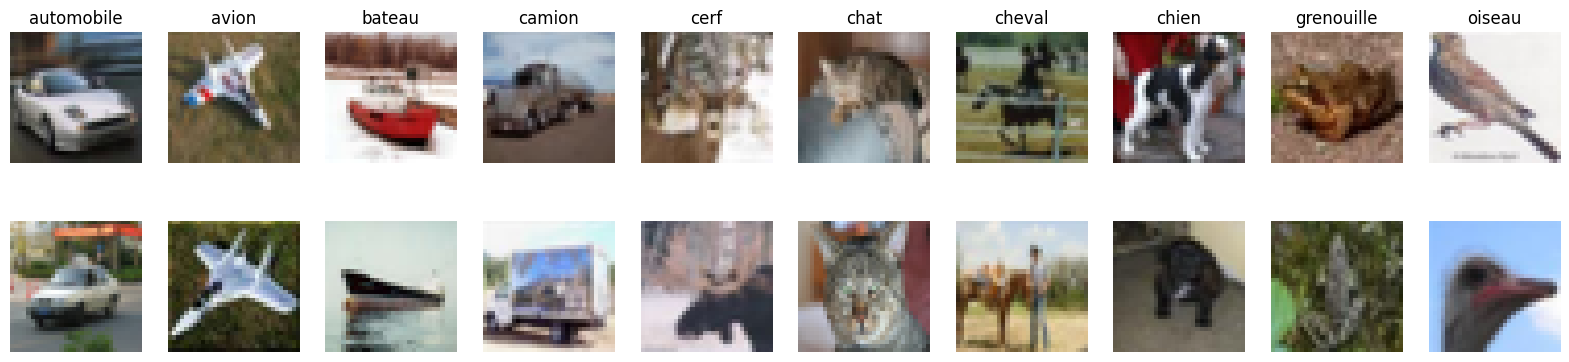

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(c.name for c in Path("cifar10/train").iterdir())
fig, axes = plt.subplots(2, 10, figsize=(20, 4.5))
for colonne, classe in enumerate(classes):
    for ligne, fichier in enumerate(sorted(Path(f"cifar10/train/{classe}").iterdir())[:2]):
        axes[ligne, colonne].imshow(Image.open(fichier))
        axes[ligne, colonne].axis("off")
    axes[0, colonne].set_title(classe)
plt.show()

Questions : les classes sont-elles équilibrées ? À 32 x 32 pixels, reconnaissez-vous chaque objet ? Quelles classes risquent d'être confondues ?

*Vos réponses :*

**Corrigé.** Les classes sont presque équilibrées : de 470 images d'entraînement (cheval) à 520 (camion), environ 500 par classe. À 32 x 32 pixels, on reconnaît la plupart des objets, mais les détails manquent : chat et chien, automobile et camion, cerf et cheval se ressemblent. Ce sont les confusions à attendre.

## Des images aux tenseurs (fourni)

Chaque image a 3 canaux de couleur de 32 x 32 pixels : aplatie, elle donne 3 x 32 x 32 = 3072 valeurs entre 0 et 1. C'est ce que lit un réseau de couches `Linear`. Les images sont servies par minibatchs de 64.

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

vers_tenseur = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])


def charger_tenseurs(partie):
    dataset = ImageFolder(f"cifar10/{partie}", transform=vers_tenseur)
    x = torch.stack([image for image, _ in dataset]).flatten(1)
    return TensorDataset(x, torch.tensor(dataset.targets))

In [7]:
torch.manual_seed(0)
train_loader = DataLoader(charger_tenseurs("train"), batch_size=64, shuffle=True)
val_loader = DataLoader(charger_tenseurs("val"), batch_size=256)
test_loader = DataLoader(charger_tenseurs("test"), batch_size=256)
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([64, 3072]) torch.Size([64])


## Entraîner et mesurer (fourni)

`evaluer` renvoie l'erreur moyenne et l'accuracy ; `fit` entraîne un modèle 20 époques, avec la boucle de la démo 5, garde l'historique et écrit les courbes pour TensorBoard sous le nom donné.

In [ ]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loss_fn = nn.CrossEntropyLoss()


def evaluer(model, loader):
    model.eval()
    total, correct = 0.0, 0
    with torch.no_grad():
        for images, labels in loader:
            scores = model(images.to(device))
            total += loss_fn(scores, labels.to(device)).item() * len(labels)
            correct += (scores.argmax(dim=1) == labels.to(device)).sum().item()
    return total / len(loader.dataset), correct / len(loader.dataset)

In [ ]:
from torch.utils.tensorboard import SummaryWriter


def fit(model, nom, n_epochs=20):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    writer = SummaryWriter(f"runs/tp2/{nom}")
    historique = {"loss_trn": [], "loss_val": [], "acc_val": []}
    for epoch in range(1, n_epochs + 1):
        model.train()
        for images, labels in train_loader:
            loss = loss_fn(model(images.to(device)), labels.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        train_loss, train_acc = evaluer(model, train_loader)
        val_loss, val_acc = evaluer(model, val_loader)
        historique["loss_trn"].append(train_loss)
        historique["loss_val"].append(val_loss)
        historique["acc_val"].append(val_acc)
        writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
        writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        print(f"époque {epoch}  loss {train_loss:.3f}  acc {train_acc:.3f}  val_loss {val_loss:.3f}  val_acc {val_acc:.3f}")
    writer.close()
    return historique

## Étape 1 : la référence à battre

Quelle accuracy obtiendrait un « modèle » qui répond toujours la classe la plus fréquente en validation ? Comptez les labels de chaque classe avec `torch.bincount`, puis divisez le plus grand effectif par le nombre de labels.

In [10]:
labels_val = val_loader.dataset.tensors[1]
reference = torch.bincount(labels_val).max().item() / len(labels_val)
print("toujours la classe la plus fréquente :", round(reference, 3))

toujours la classe la plus fréquente : 0.112


**Corrigé.** La classe la plus fréquente ne représente que 0.112 des images de validation : un modèle qui répond toujours la même classe a environ une bonne réponse sur neuf. Toute accuracy se lit par rapport à cette référence.

## Étape 2 : un premier réseau, écrit comme une classe

Complétez la classe : dans `__init__`, un `nn.Sequential` avec `Linear(3072, 128)`, `ReLU`, `Linear(128, 10)` ; dans `forward`, son appel.

In [ ]:
class Baseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.reseau = nn.Sequential(nn.Linear(3072, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.reseau(x)

In [ ]:
torch.manual_seed(0)
baseline = Baseline()
historiques = {"baseline": fit(baseline, "baseline")}
assert historiques["baseline"]["acc_val"][-1] > 0.25, "la baseline devrait dépasser 25 % en validation"

**Corrigé.** La baseline atteint 0.394 en validation : plus de trois fois la référence. Elle a appris quelque chose des pixels, mais se trompe encore sur six images sur dix.

## Étape 3 : deux couches cachées avec BatchNorm1d

Écrivez directement un `nn.Sequential` : `Linear(3072, 256)`, `BatchNorm1d(256)`, `ReLU`, puis `Linear(256, 128)`, `BatchNorm1d(128)`, `ReLU`, et `Linear(128, 10)`.

In [ ]:
torch.manual_seed(0)
deux_couches = nn.Sequential(
    nn.Linear(3072, 256), nn.BatchNorm1d(256), nn.ReLU(),
    nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(),
    nn.Linear(128, 10),
)
historiques["deux couches + BatchNorm"] = fit(deux_couches, "deux-couches-batchnorm")

## Étape 4 : trois couches cachées avec Dropout

`Linear(3072, 512)`, `Linear(512, 256)`, `Linear(256, 128)`, chacune suivie de `ReLU` et de `Dropout(0.3)`, puis `Linear(128, 10)`.

In [ ]:
torch.manual_seed(0)
trois_couches = nn.Sequential(
    nn.Linear(3072, 512), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 10),
)
historiques["trois couches + Dropout"] = fit(trois_couches, "trois-couches-dropout")

## Étape 5 : comparer (fourni)

Les courbes des trois réseaux dans TensorBoard, comme dans la démo 5 : `fit` les a écrites sous `runs/tp2/<nom>`.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs/tp2

**Corrigé.** Dans Colab, TensorBoard s'affiche sous la cellule ; ce notebook enregistré n'en garde pas l'image. Chaque réseau y a ses courbes de loss et d'accuracy, entraînement et validation : on compare les trois réseaux d'un coup d'oeil, en cochant ou décochant leurs runs.

Les mêmes courbes de loss avec Matplotlib. Trait plein : entraînement ; pointillés : validation.

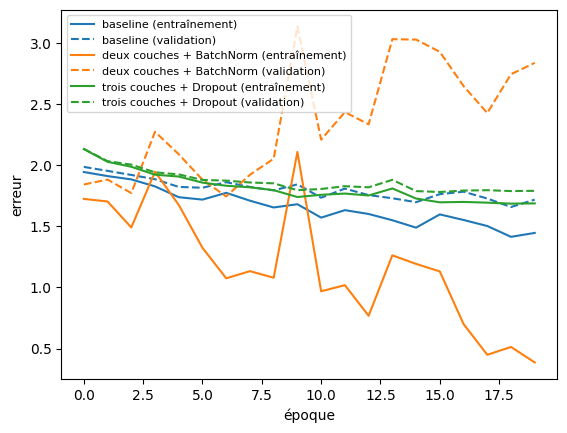

In [15]:
for nom, h in historiques.items():
    ligne, = plt.plot(h["loss_trn"], label=f"{nom} (entraînement)")
    plt.plot(h["loss_val"], "--", color=ligne.get_color(), label=f"{nom} (validation)")
plt.xlabel("époque")
plt.ylabel("erreur")
plt.legend(fontsize=8)
plt.show()

In [ ]:
for nom, h in historiques.items():
    meilleure = min(h["loss_val"])
    print(f"{nom:26s} accuracy val {h['acc_val'][-1]:.3f}  "
          f"meilleure erreur val {meilleure:.3f} (époque {h['loss_val'].index(meilleure) + 1})")

baseline                   accuracy val 0.394  meilleure erreur val 1.656 (époque 19)
deux couches + BatchNorm   accuracy val 0.373  meilleure erreur val 1.724 (époque 3)
trois couches + Dropout    accuracy val 0.343  meilleure erreur val 1.758 (époque 16)


Question : quel réseau choisissez-vous, et pourquoi ? Regardez l'écart entre entraînement et validation, l'évolution de l'erreur de validation, et la référence de l'étape 1.

*Vos conclusions :*

**Corrigé.** La baseline est la meilleure : 0.394 en validation, contre 0.373 pour deux couches avec BatchNorm et 0.343 pour trois couches avec Dropout. Le réseau avec BatchNorm surapprend très vite : son erreur de validation est minimale dès l'époque 3 (1.724), puis remonte fortement pendant que son erreur d'entraînement plonge, avec des courbes très irrégulières. Le réseau avec Dropout, à l'inverse, garde ses deux courbes proches mais hautes : il apprend peu dans le temps imparti. Plus de couches n'a pas aidé : un MLP lit les pixels un par un, sans savoir lesquels sont voisins. On retient la baseline.

## Étape 6 : une seule mesure sur le jeu de test

Le choix est fait : mesurez le modèle choisi une seule fois sur le jeu de test, avec `evaluer`.

In [16]:
modeles = {"baseline": baseline, "deux couches + BatchNorm": deux_couches, "trois couches + Dropout": trois_couches}
choix = max(historiques, key=lambda nom: historiques[nom]["acc_val"][-1])
loss_test, acc_test = evaluer(modeles[choix], test_loader)
print(f"modèle choisi : {choix}, accuracy test : {acc_test:.3f}")

modèle choisi : baseline, accuracy test : 0.397


**Corrigé.** Le corrigé retient le réseau de meilleure accuracy de validation, la baseline : 0.397 sur le test, proche de la validation. Le test confirme le choix, sans avoir servi à le faire.

## Bonus

**B1.** Comptez les paramètres de chaque réseau. Le plus gros est-il le meilleur ?

In [ ]:
for nom, modele in [("baseline", baseline), ("deux couches + BatchNorm", deux_couches),
                   ("trois couches + Dropout", trois_couches)]:
    print(f"{nom:26s} {sum(p.numel() for p in modele.parameters()):8d} paramètres")

baseline                     394634 paramètres
deux couches + BatchNorm     821642 paramètres
trois couches + Dropout     1738890 paramètres


**Corrigé.** Non : le plus gros réseau, trois couches avec Dropout (1738890 paramètres, plus de quatre fois les 394634 de la baseline), est le moins bon. Sans structure adaptée aux images, ajouter des paramètres n'apporte rien sur 5000 images.

**B2.** Et avec 50 époques ? Réentraînez la baseline avec `fit(Baseline(), "baseline-50-epoques", n_epochs=50)` et comparez l'erreur de validation.

In [ ]:
torch.manual_seed(0)
h = fit(Baseline(), "baseline-50-epoques", n_epochs=50)
meilleure = min(h["loss_val"])
print(f"meilleure erreur val {meilleure:.3f} (époque {h['loss_val'].index(meilleure) + 1}), "
      f"erreur val finale {h['loss_val'][-1]:.3f}")

**Corrigé.** Après 50 époques, l'accuracy de validation retombe à 0.388. La meilleure erreur de validation reste celle de l'époque 19 (1.656) et l'erreur finale remonte à 1.781 : entraîner plus longtemps n'aide pas, le modèle commence à surapprendre.